# Cowboy Cigarettes: A Time Series Investigation — Completed Case Study (Tier 3)

**Question:** Based solely on monthly sales recorded from 1949 through 1960, were Cowboy Cigarettes sales likely to rise, fall, or stay flat in the early 1960s?

This is a historical, out-of-sample forecast, not a claim about actual 1961–1963 sales.

## 1. Data loading and quality checks

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

raw = pd.read_csv('CowboyCigsData.csv')
print(raw.shape, raw.isna().sum().to_dict())
print(raw.head())

(144, 3) {'Unnamed: 0': 0, 'Time': 0, '#CigSales': 0}
   Unnamed: 0     Time  #CigSales
0           0  1949-01    1000112
1           1  1949-02    1000118
2           2  1949-03    1000132
3           3  1949-04    1000129
4           4  1949-05    1000121


**Important data-quality observation:** Every sales entry is exactly 1,000,000 plus a much smaller number (112 to 622). This suspicious fixed offset could be anonymization or synthetic encoding. We subtract 1,000,000 for *modeling and visual interpretation*, but retain the original scale when reporting forecasts. Because the provenance is unknown, absolute sales claims and public-health policy inferences must be qualified. The offset removal is a modeling assumption, not a verified correction.

count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: #CigSales, dtype: float64


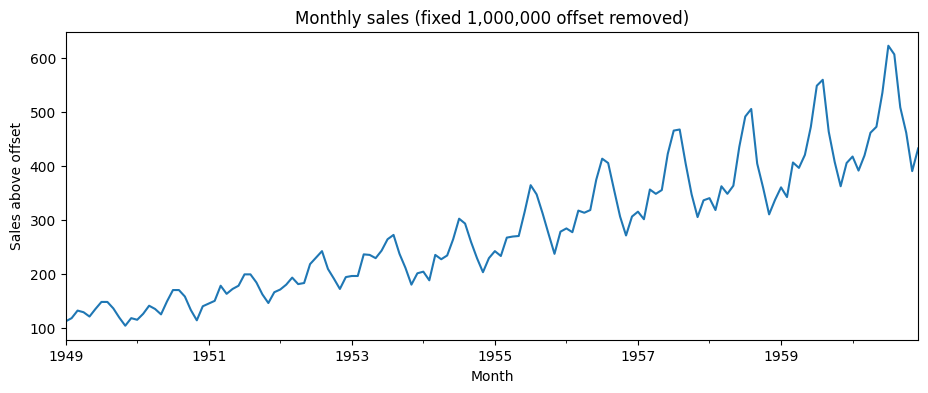

In [2]:
df = raw.drop(columns=['Unnamed: 0']).rename(columns={'Time':'Month'})
df['Month'] = pd.to_datetime(df['Month'])
df = df.set_index('Month').asfreq('MS')
y_original = df['#CigSales'].astype(float)
y = y_original - 1_000_000
assert len(y) == 144 and not y.isna().any()
print(y.describe())
fig,ax=plt.subplots(figsize=(11,4)); y.plot(ax=ax);ax.set(title='Monthly sales (fixed 1,000,000 offset removed)',ylabel='Sales above offset');plt.show()

## 2. Trend and seasonality
The 1949–1960 series rises over time and has strong annual seasonality, with summer peaks. A seasonal forecasting model is therefore preferable to a nonseasonal ARIMA-only specification.

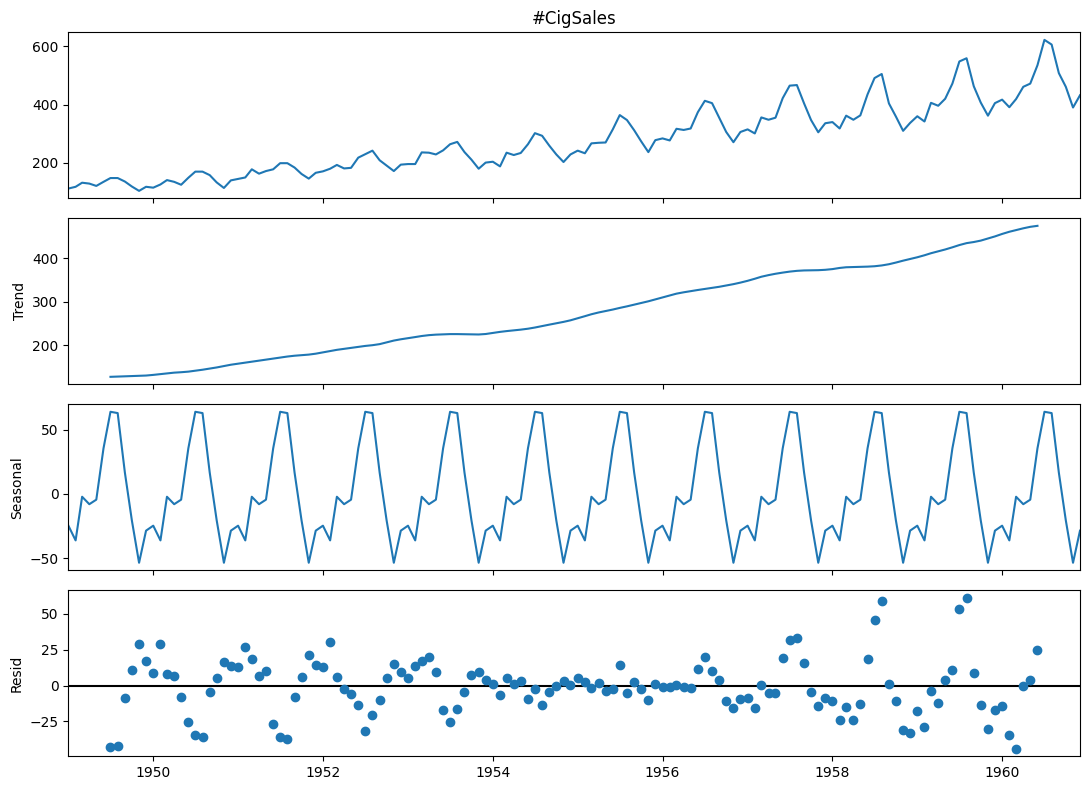

Annual mean adjusted sales:
Month
1949-01-01    126.7
1950-01-01    139.7
1951-01-01    170.2
1952-01-01    197.0
1953-01-01    225.0
1954-01-01    238.9
1955-01-01    284.0
1956-01-01    328.2
1957-01-01    368.4
1958-01-01    381.0
1959-01-01    428.3
1960-01-01    476.2
Freq: YS-JAN, Name: #CigSales, dtype: float64


In [3]:
decomp=seasonal_decompose(y,model='additive',period=12)
decomp.plot();plt.gcf().set_size_inches(11,8);plt.tight_layout();plt.show()
print('Annual mean adjusted sales:')
print(y.resample('YS').mean().round(1))

## 3. Stationarity
KPSS tests the null hypothesis of level stationarity. Differencing at lag 1 and lag 12 is used within the SARIMA specification to address trend and seasonality. KPSS warnings can indicate the test statistic lies outside its tabulated p-value range.

In [4]:
for label,series in [('Raw adjusted series',y),('First difference',y.diff().dropna()),('Seasonal and first difference',y.diff(12).diff().dropna())]:
    try:
        statistic,pvalue,*_=kpss(series,regression='c',nlags='auto')
        print(f'{label}: KPSS={statistic:.3f}, p={pvalue:.3f}')
    except Exception as exc:print(label,exc)

Raw adjusted series: KPSS=1.651, p=0.010
First difference: KPSS=0.024, p=0.100
Seasonal and first difference: KPSS=0.047, p=0.100


/var/folders/wj/2f2ds2rn2c13_ggzm3pwwhn00000gn/T/ipykernel_92327/704761219.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  statistic,pvalue,*_=kpss(series,regression='c',nlags='auto')
/var/folders/wj/2f2ds2rn2c13_ggzm3pwwhn00000gn/T/ipykernel_92327/704761219.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  statistic,pvalue,*_=kpss(series,regression='c',nlags='auto')
/var/folders/wj/2f2ds2rn2c13_ggzm3pwwhn00000gn/T/ipykernel_92327/704761219.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  statistic,pvalue,*_=kpss(series,regression='c',nlags='auto')


## 4. Time-ordered validation
Hold out the last 24 months (1959–1960) as a realistic forecast test. Train on 1949–1958, and compare several SARIMA orders with a common annual seasonal component (0,1,1,12). Select by holdout RMSE. This is a small exploratory search, not a guarantee of the globally optimal model.

In [5]:
train,test=y.iloc[:-24],y.iloc[-24:]
orders=[(0,1,1),(1,1,0),(1,1,1),(2,1,1)]
results=[]
for order in orders:
    try:
        fitted=SARIMAX(train,order=order,seasonal_order=(0,1,1,12),trend='n',enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=120)
        pred=fitted.get_forecast(steps=len(test)).predicted_mean
        results.append({'order':order,'MAE':mean_absolute_error(test,pred),'RMSE':np.sqrt(mean_squared_error(test,pred))})
    except Exception as exc:print('Failed',order,exc)
scores=pd.DataFrame(results).sort_values('RMSE')
print(scores.to_string(index=False))
best_order=scores.iloc[0]['order']
print('Selected order:',best_order)

    order       MAE      RMSE
(0, 1, 1) 66.275341 71.829443
(1, 1, 0) 67.177714 72.763978
(2, 1, 1) 68.393160 73.994757
(1, 1, 1) 68.433076 74.036480
Selected order: (0, 1, 1)


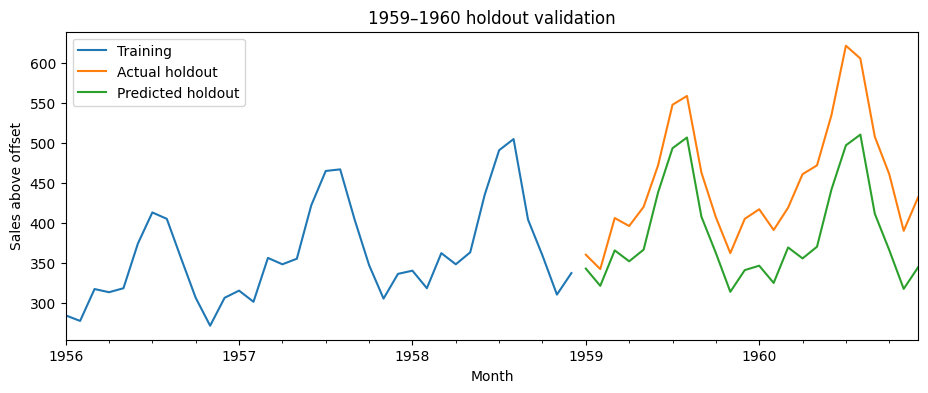

In [6]:
holdout_model=SARIMAX(train,order=best_order,seasonal_order=(0,1,1,12),trend='n',enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=120)
validation=holdout_model.get_forecast(24).predicted_mean
fig,ax=plt.subplots(figsize=(11,4));train.iloc[-36:].plot(ax=ax,label='Training');test.plot(ax=ax,label='Actual holdout');validation.plot(ax=ax,label='Predicted holdout');ax.legend();ax.set(title='1959–1960 holdout validation',ylabel='Sales above offset');plt.show()

## 5. Forecast for January 1961–December 1963
Fit the selected model on all data available through December 1960, then forecast 36 months. Intervals are model-based 95% prediction intervals, not guarantees. No observations from after 1960 are used.

Average monthly predicted sales by year:
1961-01-01    1000507.1
1962-01-01    1000539.8
1963-01-01    1000572.5
Freq: YS-JAN, Name: predicted_mean, dtype: float64
             Forecast   Lower_95   Upper_95
1961-01-01  1000447.2  1000423.6  1000470.8
1961-02-01  1000422.1  1000393.4  1000450.7
1961-03-01  1000453.9  1000421.0  1000486.7
1961-04-01  1000490.0  1000453.4  1000526.6
1961-05-01  1000502.3  1000462.3  1000542.3
1961-06-01  1000564.3  1000521.2  1000607.4
1961-07-01  1000649.8  1000603.8  1000695.9
1961-08-01  1000636.9  1000588.1  1000685.6
1961-09-01  1000539.1  1000487.7  1000590.5
1961-10-01  1000491.2  1000437.3  1000545.0
1961-11-01  1000423.1  1000366.9  1000479.3
1961-12-01  1000465.0  1000406.5  1000523.5


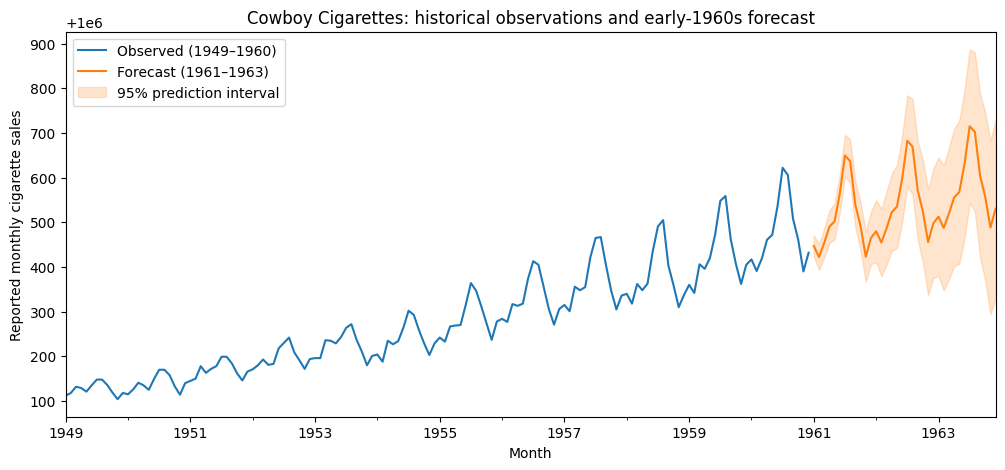

In [7]:
final_model=SARIMAX(y,order=best_order,seasonal_order=(0,1,1,12),trend='n',enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=150)
forecast_result=final_model.get_forecast(steps=36)
forecast=forecast_result.predicted_mean + 1_000_000
intervals=forecast_result.conf_int(alpha=0.05) + 1_000_000
forecast_table=pd.DataFrame({'Forecast':forecast,'Lower_95':intervals.iloc[:,0],'Upper_95':intervals.iloc[:,1]})
print('Average monthly predicted sales by year:')
print(forecast.resample('YS').mean().round(1))
print(forecast_table.head(12).round(1))
fig,ax=plt.subplots(figsize=(12,5))
y_original.plot(ax=ax,label='Observed (1949–1960)')
forecast.plot(ax=ax,label='Forecast (1961–1963)',color='tab:orange')
ax.fill_between(forecast.index,intervals.iloc[:,0].to_numpy(),intervals.iloc[:,1].to_numpy(),alpha=.2,color='tab:orange',label='95% prediction interval')
ax.set(title='Cowboy Cigarettes: historical observations and early-1960s forecast',ylabel='Reported monthly cigarette sales');ax.legend();plt.show()
forecast_table.to_csv('CowboyCigarettes_1961_1963_forecast.csv',index_label='Month')

## 6. Conclusion and limitations

**Conclusion:** The historical data show a pronounced upward trend and regular summer peaks. The fitted seasonal model projects that sales would **continue increasing** in the early 1960s, rather than decline or remain constant. This is a *probabilistic reconstruction* based on 1949–1960 information only.

**Limitations:** The dataset has a suspicious constant million-unit offset; its provenance and units cannot be independently validated here. The data are observational, not causal, and no economic, regulatory, demographic, or tobacco-industry covariates are provided. The model cannot establish actual 1961–1963 outcomes. A 24-month holdout provides one test of forecast performance but does not eliminate model risk.

**Public-health implication:** A continuing upward trajectory in this manufacturer’s recorded sales would warrant monitoring and further investigation, but cannot alone establish national cigarette consumption trends or health effects.